[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-biopython-course/blob/main/notebooks/11_phylogenetics.ipynb)

# 11 · Phylogenetics with Bio.Phylo

*Practical Biopython Course · Hamza Hentabli, Ph.D. · ~45 min*

A phylogenetic tree summarizes how sequences are related. In drug discovery, trees of a target
family (the "kinome tree" is the classic example) show which off-targets are close relatives of your
target. We build trees from the kinase-domain alignment of Notebook 07.

**Learning objectives.** By the end of this notebook you will be able to:

- compute a distance matrix from a multiple sequence alignment
- build UPGMA and neighbour-joining trees with `Bio.Phylo.TreeConstruction`
- root, draw, traverse, and save trees (Newick)
- estimate branch support with bootstrapping

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'biopython'], check=True)
    if not os.path.isdir("practical-biopython-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-biopython-course.git"], check=True)
    DATA_DIR = "practical-biopython-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. From alignment to distance matrix

In [2]:
import io
import matplotlib.pyplot as plt
from Bio import AlignIO, Phylo
from Bio.Phylo.TreeConstruction import DistanceCalculator, DistanceTreeConstructor

msa = AlignIO.read(f"{DATA_DIR}/alignments/kinase_domains_famsa.aln", "clustal")
calc = DistanceCalculator("identity")      # distance = 1 - fraction identical
dm = calc.get_distance(msa)
print(dm.names[:4])
print("EGFR_HUMAN -> ERBB2_HUMAN:", round(dm["EGFR_HUMAN", "ERBB2_HUMAN"], 3))
print("EGFR_HUMAN -> CDK2_HUMAN: ", round(dm["EGFR_HUMAN", "CDK2_HUMAN"], 3))

['EGFR_HUMAN', 'ERBB2_HUMAN', 'ERBB3_HUMAN', 'ERBB4_HUMAN']
EGFR_HUMAN -> ERBB2_HUMAN: 0.133
EGFR_HUMAN -> CDK2_HUMAN:  0.626


`DistanceCalculator` also accepts substitution models such as `"blosum62"`, which give credit for
similar (not just identical) residues. Note that gap columns count as mismatches in the `identity` model.

## 2. UPGMA and neighbour joining

In [3]:
constructor = DistanceTreeConstructor()
upgma_tree = constructor.upgma(dm)
nj_tree = constructor.nj(dm)
Phylo.draw_ascii(nj_tree)

     ___________________________________________________________ CDK2_HUMAN
  __|
 |  |__________________________________________ BRAF_HUMAN
 |
 |                       ___________ ERBB4_HUMAN
 |                      |
 |              ________|            , EGFR_MOUSE
 |             |        |   _________|
 |             |        |__|         | EGFR_HUMAN
 |           __|           |
 |          |  |           |_________ ERBB2_HUMAN
 |     _____|  |
 |    |     |  |________________________ ERBB3_HUMAN
 |____|     |
 |    |     |________________________ EGFR_DROME
 |    |
_|    |____________________________________ LET23_CAEEL
 |
 |    _______________________________ BTK_HUMAN
 |___|
 |   | ____________________________ SRC_HUMAN
 |   ||
 |    |__________________________ ABL1_HUMAN
 |
 | __________________________________ MET_HUMAN
 ||
  | _______________________________________ ALK_HUMAN
  ||
   |_____________________________________________________________ VGFR2_HUMAN



**UPGMA** assumes a constant evolutionary rate (a "molecular clock") and always produces a rooted,
ultrametric tree. **Neighbour joining (NJ)** does not assume a clock and is generally preferred for
proteins; its tree is unrooted until you choose a root.

## 3. Rooting and drawing

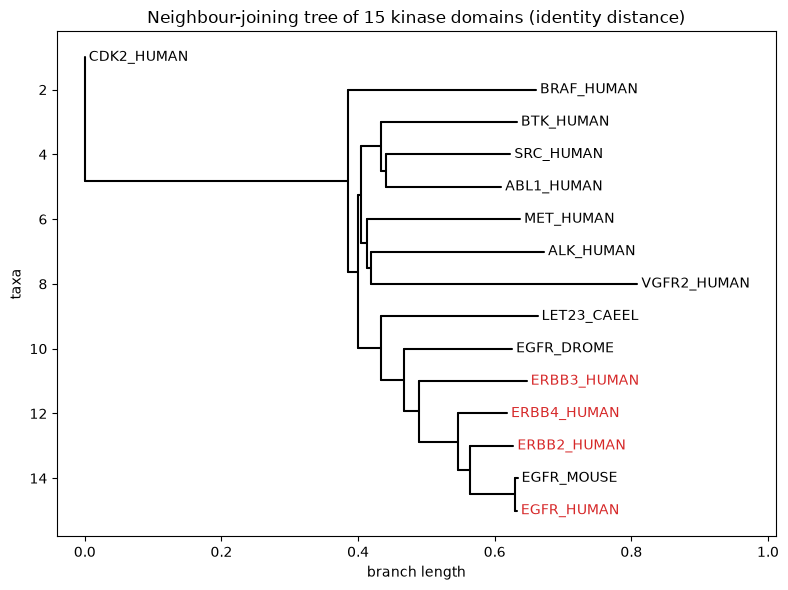

In [4]:
nj_tree.root_with_outgroup("CDK2_HUMAN")   # CDK2 is a Ser/Thr kinase, distant from the tyrosine kinases
nj_tree.ladderize()
for clade in nj_tree.get_nonterminals():
    clade.name = None                    # hide internal node labels

fig, ax = plt.subplots(figsize=(8, 6))
Phylo.draw(nj_tree, axes=ax, do_show=False,
           label_colors=lambda name: "tab:red" if name in ("EGFR_HUMAN", "ERBB2_HUMAN", "ERBB3_HUMAN", "ERBB4_HUMAN") else "black")
ax.set_title("Neighbour-joining tree of 15 kinase domains (identity distance)")
plt.tight_layout(); plt.show()

The four human ErbB receptors (red) and mouse EGFR form one group, joined next by the fly and then the worm
EGFR: a single ancestral receptor that expanded into four paralogues in vertebrates. Other receptor tyrosine kinases (VEGFR2, MET, ALK) and non-receptor tyrosine
kinases (ABL1, SRC, BTK) follow, and the Ser/Thr kinases BRAF and CDK2 are the most distant.

## 4. Working with the tree object

In [5]:
print("terminals:", len(nj_tree.get_terminals()), "| total branch length:", round(nj_tree.total_branch_length(), 3))
ca = nj_tree.common_ancestor("EGFR_HUMAN", "ERBB4_HUMAN")
print("ErbB clade members under the EGFR/ERBB4 ancestor:", [t.name for t in ca.get_terminals()])
erbb = [nj_tree.find_any(n) for n in ["EGFR_HUMAN", "ERBB2_HUMAN", "ERBB3_HUMAN", "ERBB4_HUMAN", "EGFR_MOUSE"]]
print("are the vertebrate ErbB sequences monophyletic?", bool(nj_tree.is_monophyletic(erbb)))  # pass clades, not strings
print("tree distance EGFR_HUMAN-EGFR_MOUSE:", round(nj_tree.distance("EGFR_HUMAN", "EGFR_MOUSE"), 3),
      "| EGFR_HUMAN-ABL1_HUMAN:", round(nj_tree.distance("EGFR_HUMAN", "ABL1_HUMAN"), 3))

terminals: 15 | total branch length: 3.065
ErbB clade members under the EGFR/ERBB4 ancestor: ['ERBB4_HUMAN', 'ERBB2_HUMAN', 'EGFR_MOUSE', 'EGFR_HUMAN']
are the vertebrate ErbB sequences monophyletic? True
tree distance EGFR_HUMAN-EGFR_MOUSE: 0.008 | EGFR_HUMAN-ABL1_HUMAN: 0.442


## 5. Saving and reading Newick

In [6]:
import os
os.makedirs("output", exist_ok=True)
Phylo.write(nj_tree, "output/kinase_nj.nwk", "newick")
print(open("output/kinase_nj.nwk").read()[:200], "...")
reloaded = Phylo.read("output/kinase_nj.nwk", "newick")
print("reloaded terminals:", len(reloaded.get_terminals()))

(CDK2_HUMAN:0,(BRAF_HUMAN:0.27554294,(((BTK_HUMAN:0.19849,(SRC_HUMAN:0.1817805,ABL1_HUMAN:0.16835212):0.007080294):0.030081751,(MET_HUMAN:0.22416902,(ALK_HUMAN:0.25263698,VGFR2_HUMAN:0.38927284):0.006 ...
reloaded terminals: 15


Newick files open in iTOL, FigTree, or Dendroscope for publication-quality figures.

## 6. Bootstrap support

How much should we trust each branch? Bootstrapping resamples alignment columns with replacement,
rebuilds the tree each time, and counts how often each clade reappears.

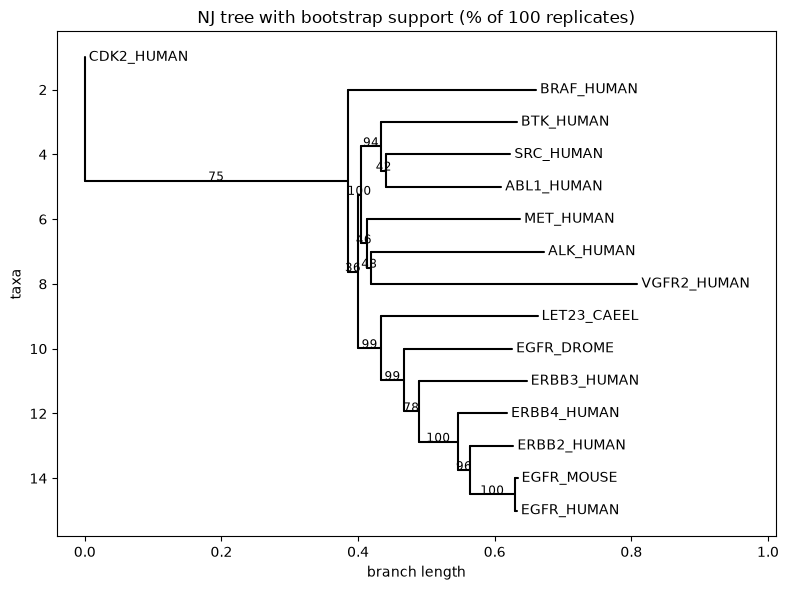

In [7]:
from Bio.Phylo.Consensus import bootstrap_trees, get_support
import random
random.seed(42)                          # reproducible resampling

N_BOOT = 100
replicates = list(bootstrap_trees(msa, N_BOOT, DistanceTreeConstructor(calc, "nj")))
support_tree = get_support(constructor.nj(dm), replicates)
support_tree.root_with_outgroup("CDK2_HUMAN")
support_tree.ladderize()
for clade in support_tree.get_nonterminals():
    clade.name = None
    if clade.confidence is not None:
        clade.confidence = round(clade.confidence)
fig, ax = plt.subplots(figsize=(8, 6))
Phylo.draw(support_tree, axes=ax, do_show=False)
ax.set_title(f"NJ tree with bootstrap support (% of {N_BOOT} replicates)")
plt.tight_layout(); plt.show()

Support close to 100 means the grouping is robust to column resampling; values below ~70 should be
interpreted cautiously. Deep splits among distantly related kinases are usually less certain than the
recent, well-supported ErbB/ortholog groupings.

### ✏️ Exercise 1

Rebuild the NJ tree with the `"blosum62"` distance model. Is EGFR still closest to EGFR_MOUSE, and is the
ErbB group still monophyletic?

In [8]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
dm62 = DistanceCalculator("blosum62").get_distance(msa)
t62 = DistanceTreeConstructor().nj(dm62)
t62.root_with_outgroup("CDK2_HUMAN")
others = [n for n in dm62.names if n != "EGFR_HUMAN"]
print("closest to EGFR:", min(others, key=lambda n: t62.distance("EGFR_HUMAN", n)))
print("monophyletic ErbB:", bool(t62.is_monophyletic([t62.find_any(n) for n in
      ["EGFR_HUMAN", "ERBB2_HUMAN", "ERBB3_HUMAN", "ERBB4_HUMAN", "EGFR_MOUSE"]])))
Phylo.draw_ascii(t62)
```

</details>

### ✏️ Exercise 2

Draw the **UPGMA** tree with `Phylo.draw` and compare it with the NJ tree. Which grouping differs?

In [9]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
fig, ax = plt.subplots(figsize=(8, 6))
Phylo.draw(upgma_tree, axes=ax, do_show=False)
plt.show()
```

</details>

### ✏️ Exercise 3

List every terminal with its distance from the root of `nj_tree`, sorted from nearest to farthest.

In [10]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
depths = nj_tree.depths()
for t in sorted(nj_tree.get_terminals(), key=lambda t: depths[t]):
    print(f"{t.name:<13} {depths[t]:.3f}")
```

</details>

## Key takeaways

- `DistanceCalculator` → `DistanceTreeConstructor` (UPGMA or NJ) → `Phylo.draw`.
- Root with a sensible outgroup; NJ trees are unrooted until you do.
- Bootstrap support tells you which branches to trust.

**Next:** [12 · Mini project](12_mini_project_target_to_structure.ipynb).